In [1]:
import os
import torch
import numpy as np
import matplotlib.pyplot as plt

from torchvision import datasets, transforms
from torch.utils.data import DataLoader


In [2]:
from PIL import ImageFile

ImageFile.LOAD_TRUNCATED_IMAGES = True

print("Configuración aplicada correctamente")

Configuración aplicada correctamente


In [3]:
dataset_path = os.path.join(
    "Bone_Fracture_Binary_Classification",
    "Bone_Fracture_Binary_Classification"
)

for carpeta in ["train", "val", "test"]:
    ruta = os.path.join(dataset_path, carpeta)

    print(f"\n{carpeta.upper()}")

    if os.path.exists(ruta):
        print(os.listdir(ruta))
    else:
        print("No se encontró esta carpeta")



TRAIN
['fractured', 'not fractured']

VAL
['fractured', 'not fractured']

TEST
['fractured', 'not fractured']


In [4]:

# Transformaciones para preparar las radiografías
transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

# Cargar los conjuntos de imágenes
trainset = datasets.ImageFolder(
    os.path.join(dataset_path, "train"),
    transform=transform
)

valset = datasets.ImageFolder(
    os.path.join(dataset_path, "val"),
    transform=transform
)

testset = datasets.ImageFolder(
    os.path.join(dataset_path, "test"),
    transform=transform
)

# Crear los cargadores de datos
trainloader = DataLoader(
    trainset,
    batch_size=32,
    shuffle=True,
    num_workers=0
)
valloader = DataLoader(valset, batch_size=32, shuffle=False)
testloader = DataLoader(testset, batch_size=32, shuffle=False)

# Mostrar información del dataset
print("Clases:", trainset.classes)
print("Imágenes de entrenamiento:", len(trainset))
print("Imágenes de validación:", len(valset))
print("Imágenes de prueba:", len(testset))


Clases: ['fractured', 'not fractured']
Imágenes de entrenamiento: 9246
Imágenes de validación: 829
Imágenes de prueba: 506


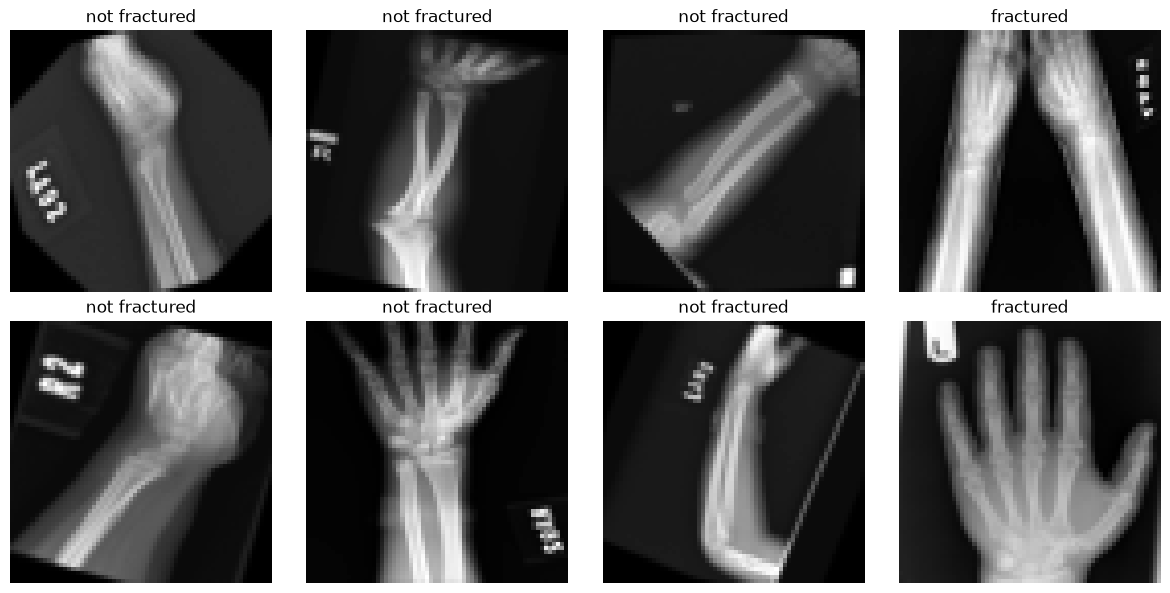

In [5]:

# Obtener un lote de imágenes
images, labels = next(iter(trainloader))

# Mostrar las primeras 8 radiografías
fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].squeeze(), cmap="gray")

    clase = trainset.classes[labels[i].item()]
    ax.set_title(clase)
    ax.axis("off")

plt.tight_layout()
plt.show()


In [6]:

import torch.nn as nn

model = nn.Sequential(
    nn.Linear(64 * 64, 128),
    nn.ReLU(),
    nn.Linear(128, 64),
    nn.ReLU(),
    nn.Linear(64, 2)
)

print(model)


Sequential(
  (0): Linear(in_features=4096, out_features=128, bias=True)
  (1): ReLU()
  (2): Linear(in_features=128, out_features=64, bias=True)
  (3): ReLU()
  (4): Linear(in_features=64, out_features=2, bias=True)
)


In [7]:

# Función de pérdida
criterion = nn.CrossEntropyLoss()

# Optimizador
optimizer = torch.optim.SGD(model.parameters(), lr=0.01)

print("Función de pérdida:", criterion)
print("Optimizador:", optimizer)


Función de pérdida: CrossEntropyLoss()
Optimizador: SGD (
Parameter Group 0
    dampening: 0
    differentiable: False
    foreach: None
    fused: None
    lr: 0.01
    maximize: False
    momentum: 0
    nesterov: False
    weight_decay: 0
)


In [8]:

# Obtener un lote de radiografías
images, labels = next(iter(trainloader))

print("Forma original:", images.shape)
print("Forma de las etiquetas:", labels.shape)

# Convertir cada imagen en un vector de 4096 valores
images = images.view(images.shape[0], -1)

print("Forma después de aplanar:", images.shape)

# Realizar una primera predicción
logits = model(images)

print("Forma de la salida:", logits.shape)


Forma original: torch.Size([32, 1, 64, 64])
Forma de las etiquetas: torch.Size([32])
Forma después de aplanar: torch.Size([32, 4096])
Forma de la salida: torch.Size([32, 2])


In [9]:

epochs = 5

train_losses = []

for epoch in range(epochs):
    running_loss = 0

    for images, labels in trainloader:
        # Aplanar las imágenes
        images = images.view(images.shape[0], -1)

        # Limpiar los gradientes anteriores
        optimizer.zero_grad()

        # Propagación hacia adelante
        logits = model(images)

        # Calcular la pérdida
        loss = criterion(logits, labels)

        # Retropropagación
        loss.backward()

        # Actualizar los parámetros
        optimizer.step()

        running_loss += loss.item()

    epoch_loss = running_loss / len(trainloader)
    train_losses.append(epoch_loss)

    print(f"Época {epoch + 1}: pérdida = {epoch_loss:.4f}")


Época 1: pérdida = 0.6384
Época 2: pérdida = 0.5418
Época 3: pérdida = 0.4763
Época 4: pérdida = 0.4200
Época 5: pérdida = 0.3657


In [11]:

correct = 0
total = 0

with torch.no_grad():
    for images, labels in testloader:
        images = images.view(images.shape[0], -1)

        logits = model(images)
        predictions = torch.argmax(logits, dim=1)

        total += labels.size(0)
        correct += (predictions == labels).sum().item()

accuracy = correct / total

print("Imágenes evaluadas:", total)
print(f"Aciertos: {correct}")
print(f"Precisión: {accuracy:.4f}")
print(f"Precisión porcentual: {accuracy * 100:.2f}%")


Imágenes evaluadas: 506
Aciertos: 390
Precisión: 0.7708
Precisión porcentual: 77.08%


In [ ]:
# Exactitud en el conjunto de validación (no se reentrena el modelo)
val_correct = 0
val_total = 0

with torch.no_grad():
    for images, labels in valloader:
        images = images.view(images.shape[0], -1)
        predictions = torch.argmax(model(images), dim=1)
        val_total += labels.size(0)
        val_correct += (predictions == labels).sum().item()

print("Imágenes de validación evaluadas:", val_total)
print(f"Exactitud en validación: {val_correct / val_total * 100:.2f}%")

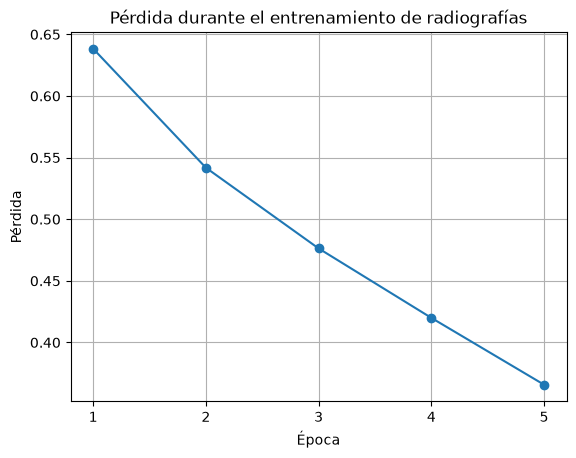

In [12]:

plt.plot(
    range(1, len(train_losses) + 1),
    train_losses,
    marker="o"
)

plt.xlabel("Época")
plt.ylabel("Pérdida")
plt.title("Pérdida durante el entrenamiento de radiografías")
plt.xticks(range(1, len(train_losses) + 1))
plt.grid(True)
plt.show()


In [13]:

from sklearn.metrics import classification_report, confusion_matrix

all_labels = []
all_predictions = []

with torch.no_grad():
    for images, labels in testloader:
        images = images.view(images.shape[0], -1)

        logits = model(images)
        predictions = torch.argmax(logits, dim=1)

        all_labels.extend(labels.tolist())
        all_predictions.extend(predictions.tolist())

print("Orden de las clases:", testset.classes)

print("\nReporte de clasificación:")
print(classification_report(
    all_labels,
    all_predictions,
    target_names=testset.classes,
    zero_division=0
))

print("\nMatriz de confusión:")
print(confusion_matrix(all_labels, all_predictions))


Orden de las clases: ['fractured', 'not fractured']

Reporte de clasificación:
               precision    recall  f1-score   support

    fractured       0.75      0.76      0.76       238
not fractured       0.79      0.78      0.78       268

     accuracy                           0.77       506
    macro avg       0.77      0.77      0.77       506
 weighted avg       0.77      0.77      0.77       506


Matriz de confusión:
[[182  56]
 [ 60 208]]
